In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 12장 텐서플로를 이용한 사용자 정의 모델과 훈련

### 12.2 넘파이처럼 텐서플로 사용하기

### 12.2.1 텐서와 연산

In [2]:
t = tf.constant([[1., 2., 3.], [4., 5., 6.]])
t

<tf.Tensor: shape=(2, 3), dtype=float32, numpy=
array([[1., 2., 3.],
       [4., 5., 6.]], dtype=float32)>

In [3]:
t.shape

TensorShape([2, 3])

In [4]:
t.dtype

tf.float32

In [5]:
t[:, 1:]

<tf.Tensor: shape=(2, 2), dtype=float32, numpy=
array([[2., 3.],
       [5., 6.]], dtype=float32)>

In [6]:
t[..., 1, tf.newaxis]

<tf.Tensor: shape=(2, 1), dtype=float32, numpy=
array([[2.],
       [5.]], dtype=float32)>

In [7]:
t + 10

<tf.Tensor: shape=(2, 3), dtype=float32, numpy=
array([[11., 12., 13.],
       [14., 15., 16.]], dtype=float32)>

In [8]:
tf.square(t)

<tf.Tensor: shape=(2, 3), dtype=float32, numpy=
array([[ 1.,  4.,  9.],
       [16., 25., 36.]], dtype=float32)>

In [9]:
t @ tf.transpose(t)

<tf.Tensor: shape=(2, 2), dtype=float32, numpy=
array([[14., 32.],
       [32., 77.]], dtype=float32)>

In [10]:
tf.constant(42)

<tf.Tensor: shape=(), dtype=int32, numpy=42>

### 12.2.2 텐서와 넘파이

In [11]:
a = np.array([2., 4., 5.])

In [12]:
tf.constant(a)

<tf.Tensor: shape=(3,), dtype=float64, numpy=array([2., 4., 5.])>

In [13]:
t.numpy()

array([[1., 2., 3.],
       [4., 5., 6.]], dtype=float32)

In [14]:
np.array(t)

array([[1., 2., 3.],
       [4., 5., 6.]], dtype=float32)

In [15]:
tf.square(a)

<tf.Tensor: shape=(3,), dtype=float64, numpy=array([ 4., 16., 25.])>

In [16]:
np.square(t)

array([[ 1.,  4.,  9.],
       [16., 25., 36.]], dtype=float32)

### 12.2.3 타입 변환

In [17]:
tf.constant(2.) + tf.constant(40., dtype=tf.float32)

<tf.Tensor: shape=(), dtype=float32, numpy=42.0>

In [18]:
t2 = tf.constant(40., dtype=tf.float64)
tf.constant(2.) + tf.cast(t2, tf.float32)

<tf.Tensor: shape=(), dtype=float32, numpy=42.0>

### 12.2.4 변수

In [19]:
v = tf.Variable([[1., 2., 3.], [4., 5., 6.]])
v

<tf.Variable 'Variable:0' shape=(2, 3) dtype=float32, numpy=
array([[1., 2., 3.],
       [4., 5., 6.]], dtype=float32)>

In [20]:
v.assign(2 * v)

<tf.Variable 'UnreadVariable' shape=(2, 3) dtype=float32, numpy=
array([[ 2.,  4.,  6.],
       [ 8., 10., 12.]], dtype=float32)>

In [21]:
v[0, 1].assign(42)

<tf.Variable 'UnreadVariable' shape=(2, 3) dtype=float32, numpy=
array([[ 2., 42.,  6.],
       [ 8., 10., 12.]], dtype=float32)>

In [22]:
v[:, 2].assign([0., 1.])

<tf.Variable 'UnreadVariable' shape=(2, 3) dtype=float32, numpy=
array([[ 2., 42.,  0.],
       [ 8., 10.,  1.]], dtype=float32)>

In [23]:
v.scatter_nd_update(indices=[[0, 0], [1, 2]],
                    updates=[100., 200.])

<tf.Variable 'UnreadVariable' shape=(2, 3) dtype=float32, numpy=
array([[100.,  42.,   0.],
       [  8.,  10., 200.]], dtype=float32)>

## 12.3 사용자 정의 모델과 훈련 알고리즘

### 12.3.1 사용자 정의 손실 함수

In [24]:
def huber_fn(y_true, y_pred):
    error = y_true - y_pred
    is_small_error = tf.abs(error) < 1
    squared_loss = tf.square(error) / 2
    linear_loss = tf.abs(error) - 0.5
    return tf.where(is_small_error, squared_loss, linear_loss)

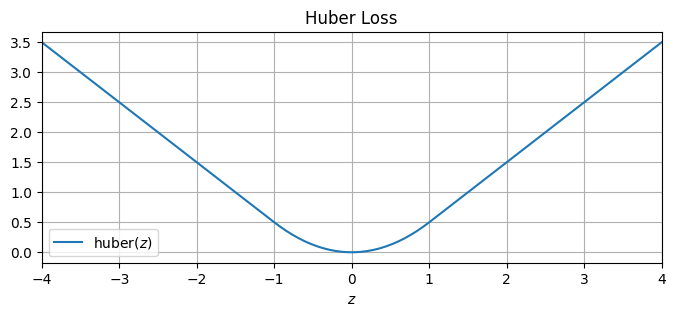

In [25]:
z = np.linspace(-4, 4, 100)
plt.figure(figsize=(8, 3))
plt.title('Huber Loss')
plt.plot(z, huber_fn(0, z), label='huber($z$)')
plt.xlabel('$z$')
plt.legend()
plt.xlim(-4, 4)
plt.grid()
plt.show()

In [26]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

housing = fetch_california_housing()
X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data, housing.target.reshape(-1, 1), random_state=42)
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

tf.keras.utils.set_random_seed(42)
model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=X_train.shape[1:]),
    tf.keras.layers.Dense(30, activation="relu", kernel_initializer="he_normal"),
    tf.keras.layers.Dense(1),
])

In [27]:
model.compile(loss=huber_fn, optimizer='nadam', metrics=['mae'])
history = model.fit(X_train, y_train, epochs=2, validation_data=(X_valid, y_valid))

Epoch 1/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 655us/step - loss: 102.1857 - mae: 102.6694 - val_loss: 2.9838 - val_mae: 3.4552
Epoch 2/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 497us/step - loss: 2.1398 - mae: 2.5938 - val_loss: 2.2224 - val_mae: 2.6903


### 12.3.2 사용자 정의 요소를 가진 모델을 저장하고 로드하기

In [28]:
model.save('my_model_with_a_custom_loss.keras')

In [29]:
model = tf.keras.models.load_model('my_model_with_a_custom_loss.keras',
                                   custom_objects={'huber_fn': huber_fn})

history = model.fit(X_train, y_train, epochs=2, validation_data=(X_valid, y_valid))

Epoch 1/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 647us/step - loss: 1.5712 - mae: 2.0133 - val_loss: 1.9288 - val_mae: 2.3780
Epoch 2/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 487us/step - loss: 1.3812 - mae: 1.8177 - val_loss: 2.3431 - val_mae: 2.8059


In [30]:
@tf.keras.utils.register_keras_serializable()
def huber_fn(y_true, y_pred):
    error = y_true - y_pred
    is_small_error = tf.abs(error) < 1
    squared_loss = tf.square(error) / 2
    linear_loss = tf.abs(error) - 0.5
    return tf.where(is_small_error, squared_loss, linear_loss)

model.compile(loss=huber_fn, optimizer='nadam', metrics=['mae'])
history = model.fit(X_train, y_train, epochs=2, validation_data=(X_valid, y_valid))

model.save('my_model_with_a_custom_loss.keras')

model = tf.keras.models.load_model('my_model_with_a_custom_loss.keras')

Epoch 1/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 649us/step - loss: 1.2914 - mae: 1.7227 - val_loss: 2.0343 - val_mae: 2.4888
Epoch 2/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 488us/step - loss: 1.1055 - mae: 1.5322 - val_loss: 1.9692 - val_mae: 2.4200


In [31]:
def create_huber(threshold=1.0):
    def huber_fn(y_true, y_pred):
        error = y_true - y_pred
        is_small_error = tf.abs(error) < threshold
        squared_loss = tf.square(error) / 2
        linear_loss = threshold * tf.abs(error) - threshold ** 2 / 2
        return tf.where(is_small_error, squared_loss, linear_loss)
    return huber_fn

model.compile(loss=create_huber(2.0), optimizer='nadam', metrics=['mae'])
history = model.fit(X_train, y_train, epochs=2, validation_data=(X_valid, y_valid))

model.save('my_model_with_a_custom_loss.keras')

model = tf.keras.models.load_model('my_model_with_a_custom_loss.keras',
                                   custom_objects={'huber_fn': create_huber(2.0)})

Epoch 1/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 645us/step - loss: 1.7794 - mae: 1.6097 - val_loss: 2.6593 - val_mae: 2.0943
Epoch 2/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 486us/step - loss: 1.4682 - mae: 1.4341 - val_loss: 1.8684 - val_mae: 1.7010


In [32]:
class HuberLoss(tf.keras.losses.Loss):
    def __init__(self, threshold=1.0, **kwargs):
        self.threshold = threshold
        super().__init__(**kwargs)

    def call(self, y_true, y_pred):
        error = y_true - y_pred
        is_small_error = tf.abs(error) < self.threshold
        squared_loss = tf.square(error) / 2
        linear_loss = self.threshold * tf.abs(error) - self.threshold ** 2 / 2
        return tf.where(is_small_error, squared_loss, linear_loss)

    def get_config(self):
        base_config = super().get_config()
        return {**base_config, 'threshold': self.threshold}

model.compile(loss=HuberLoss(2.0), optimizer='nadam', metrics=['mae'])
history = model.fit(X_train, y_train, epochs=2, validation_data=(X_valid, y_valid))

model.save('my_model_with_a_custom_loss.keras')

model = tf.keras.models.load_model('my_model_with_a_custom_loss.keras',
                                   custom_objects={'HuberLoss': HuberLoss})

Epoch 1/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 650us/step - loss: 1.7149 - mae: 1.5663 - val_loss: 2.8975 - val_mae: 2.2344
Epoch 2/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 491us/step - loss: 1.4590 - mae: 1.4262 - val_loss: 2.9919 - val_mae: 2.2880


In [33]:
@tf.keras.utils.register_keras_serializable()
class HuberLoss(tf.keras.losses.Loss):
    def __init__(self, threshold=1.0, **kwargs):
        self.threshold = threshold
        super().__init__(**kwargs)

    def call(self, y_true, y_pred):
        error = y_true - y_pred
        is_small_error = tf.abs(error) < self.threshold
        squared_loss = tf.square(error) / 2
        linear_loss = self.threshold * tf.abs(error) - self.threshold ** 2 / 2
        return tf.where(is_small_error, squared_loss, linear_loss)

    def get_config(self):
        base_config = super().get_config()
        return {**base_config, 'threshold': self.threshold}

model.compile(loss=HuberLoss(2.0), optimizer='nadam', metrics=['mae'])
history = model.fit(X_train, y_train, epochs=2, validation_data=(X_valid, y_valid))

model.save('my_model_with_a_custom_loss.keras')

model = tf.keras.models.load_model('my_model_with_a_custom_loss.keras')

Epoch 1/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 658us/step - loss: 1.6591 - mae: 1.5270 - val_loss: 2.9747 - val_mae: 2.2747
Epoch 2/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 489us/step - loss: 1.4224 - mae: 1.4017 - val_loss: 3.1261 - val_mae: 2.3654


In [34]:
model.loss.get_config().keys()

dict_keys(['name', 'reduction', 'threshold'])

### 12.3.3 활성화 함수, 초기화, 규제, 제한을 커스터마이징하기

In [35]:
def my_softplus(z):
    return tf.math.log(1.0 + tf.exp(z))

def my_glorot_initializer(shape, dtype=tf.float32):
    stddev = tf.sqrt(2. / (shape[0] + shape[1]))
    return tf.random.normal(shape, stddev=stddev, dtype=dtype)

def my_l1_regularizer(weights):
    return tf.reduce_sum(tf.abs(0.01 * weights))

def my_positive_weights(weights):
    return tf.where(weights < 0., tf.zeros_like(weights), weights)

In [36]:
layer = tf.keras.layers.Dense(1, activation=my_softplus,
                              kernel_initializer=my_glorot_initializer,
                              kernel_regularizer=my_l1_regularizer,
                              kernel_constraint=my_positive_weights)

In [37]:
class MyL1Regulizer(tf.keras.regularizers.Regularizer):
    def __init__(self, factor):
        self.factor = factor

    def call(self, weights):
        return tf.reduce_sum(tf.abs(self.factor * weights))

    def get_config(self):
        return {'factor': self.factor}

### 12.3.4 사용자 정의 지표

In [38]:
precision = tf.keras.metrics.Precision()
precision([0, 1, 1, 1, 0, 1, 0, 1], [1, 1, 0, 1, 0, 1, 0, 1])

<tf.Tensor: shape=(), dtype=float32, numpy=0.800000011920929>

In [39]:
precision([0, 1, 0, 0, 1, 0, 1, 1], [1, 0, 1, 1, 0, 0, 0, 0])

<tf.Tensor: shape=(), dtype=float32, numpy=0.5>

In [40]:
precision.result()

<tf.Tensor: shape=(), dtype=float32, numpy=0.5>

In [41]:
precision.variables

[<Variable path=precision/true_positives, shape=(1,), dtype=float32, value=[4.]>,
 <Variable path=precision/false_positives, shape=(1,), dtype=float32, value=[4.]>]

In [42]:
precision.reset_state()

precision.variables

[<Variable path=precision/true_positives, shape=(1,), dtype=float32, value=[0.]>,
 <Variable path=precision/false_positives, shape=(1,), dtype=float32, value=[0.]>]

In [43]:
class HuberMetric(tf.keras.metrics.Metric):
    def __init__(self, threshold=1.0, **kwargs):
        super().__init__(**kwargs)
        self.threshold = threshold
        self.huber_fn = create_huber(threshold)
        self.total = self.add_weight((), name='total', initializer='zeros')
        self.count = self.add_weight((), name='count', initializer='zeros')

    def update_state(self, y_true, y_pred, sample_weight=None):
        sample_metrics = self.huber_fn(y_true, y_pred)
        self.total.assign_add(tf.reduce_sum(sample_metrics))
        self.count.assign_add(tf.cast(tf.size(y_true), tf.float32))

    def result(self):
        return self.total / self.count

    def get_config(self):
        base_config = super().get_config()
        return {**base_config, 'threshold': self.threshold}

In [44]:
m = HuberMetric(2.)

# total = 14
# count = 1
# result = 14 / 1 = 14
m(tf.constant([[2.]]), tf.constant([[10.]]))

<tf.Tensor: shape=(), dtype=float32, numpy=14.0>

In [45]:
# total = total + 7 = 21
# count = count + 2 = 3
# result = 21 / 3 = 7
m(tf.constant([[0.], [5.]]), tf.constant([[1.], [9.25]]))

<tf.Tensor: shape=(), dtype=float32, numpy=7.0>

In [46]:
m.result()

<tf.Tensor: shape=(), dtype=float32, numpy=7.0>

In [47]:
m.variables

[<Variable path=huber_metric/total, shape=(), dtype=float32, value=21.0>,
 <Variable path=huber_metric/count, shape=(), dtype=float32, value=3.0>]

In [48]:
m.reset_state()

m.variables

[<Variable path=huber_metric/total, shape=(), dtype=float32, value=0.0>,
 <Variable path=huber_metric/count, shape=(), dtype=float32, value=0.0>]

In [49]:
class HuberMetric(tf.keras.metrics.Mean):
    def __init__(self, threshold=1.0, **kwargs):
        super().__init__(**kwargs)
        self.threshold = threshold
        self.huber_fn = create_huber(threshold)

    def update_state(self, y_true, y_pred, sample_weight=None):
        metric = self.huber_fn(y_true, y_pred)
        super().update_state(metric, sample_weight)

    def get_config(self):
        base_config = super().get_config()
        return {**base_config, 'threshold': self.threshold}

In [50]:
m = HuberMetric(2.)

m(tf.constant([[2.]]), tf.constant([[10.]]))
m(tf.constant([[0.], [5.]]), tf.constant([[1.], [9.25]]))

m.result()

<tf.Tensor: shape=(), dtype=float32, numpy=7.0>

### 12.3.5 사용자 정의 층

In [51]:
exponential_layer = tf.keras.layers.Lambda(lambda x: tf.exp(x))

In [52]:
@tf.keras.utils.register_keras_serializable()
class MyDense(tf.keras.layers.Layer):
    def __init__(self, units, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.activation = tf.keras.activations.get(activation)

    def build(self, batch_input_shape):
        self.kernel = self.add_weight([batch_input_shape[-1], self.units], name='kernel',
                                      initializer='glorot_normal')
        self.bias = self.add_weight([self.units], name='bias', initializer='zeros')
        super().build(batch_input_shape)

    def call(self, X):
        return self.activation(X @ self.kernel + self.bias)

    def get_config(self):
        base_config = super().get_config()
        return {**base_config, 'units': self.units,
                'activation': tf.keras.activations.serialize(self.activation)}

In [53]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1:])),
    MyDense(30, activation='relu'),
    MyDense(1)
])

model.compile(loss='mse', optimizer='nadam')
history = model.fit(X_train, y_train, epochs=2, validation_data=(X_valid, y_valid))
model.evaluate(X_test, y_test)
model.save('my_model_with_a_custom_layer.keras')

Epoch 1/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 577us/step - loss: 10721.5645 - val_loss: 12.3390
Epoch 2/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 450us/step - loss: 2.2150 - val_loss: 6.4584
162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 286us/step - loss: 1.7692


In [54]:
model = tf.keras.models.load_model('my_model_with_a_custom_layer.keras')
history = model.fit(X_train, y_train, epochs=2, validation_data=(X_valid, y_valid))

Epoch 1/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 576us/step - loss: 1.6848 - val_loss: 4.0302
Epoch 2/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 444us/step - loss: 1.4251 - val_loss: 2.5636


In [55]:
class MyMultiLayer(tf.keras.layers.Layer):
    def call(self, X):
        X1, X2 = X
        return X1 + X2, X1 * X2, X1 / X2

In [56]:
X1 = tf.constant([[1., 2.], [3., 4.]])
X2 = tf.constant([[2., 4.], [1., 2.]])
MyMultiLayer()((X1, X2))

(<tf.Tensor: shape=(2, 2), dtype=float32, numpy=
 array([[3., 6.],
        [4., 6.]], dtype=float32)>,
 <tf.Tensor: shape=(2, 2), dtype=float32, numpy=
 array([[2., 8.],
        [3., 8.]], dtype=float32)>,
 <tf.Tensor: shape=(2, 2), dtype=float32, numpy=
 array([[0.5, 0.5],
        [3. , 2. ]], dtype=float32)>)

In [57]:
class MyGaussianNoise(tf.keras.layers.Layer):
    def __init__(self, stddev, **kwargs):
        super().__init__(**kwargs)
        self.stddev = stddev

    def call(self, X, traning=False):
        if training:
            noise = tf.random.normal(tf.shape(X), stddev=self.stddev)
            return X + noise
        else:
            return X

### 12.3.6 사용자 정의 모델

In [58]:
class ResidualBlock(tf.keras.layers.Layer):
    def __init__(self, n_layers, n_neurons, **kwargs):
        super().__init__(**kwargs)
        self.hidden = [tf.keras.layers.Dense(n_neurons, activation='relu',
                                             kernel_initializer='he_normal')
                       for _ in range(n_layers)]

    def call(self, inputs):
        Z = inputs
        for layer in self.hidden:
            Z = layer(Z)
        return Z + inputs

In [59]:
@tf.keras.utils.register_keras_serializable()
class ResidualRegressor(tf.keras.models.Model):
    def __init__(self, output_dim, **kwargs):
        super().__init__(**kwargs)
        self.output_dim = output_dim
        self.hidden = tf.keras.layers.Dense(30, activation='relu',
                                            kernel_initializer='he_normal')
        self.block1 = ResidualBlock(2, 30)
        self.block2 = ResidualBlock(2, 30)
        self.out = tf.keras.layers.Dense(output_dim)

    def call(self, inputs):
        Z = self.hidden(inputs)
        for _ in range(4):
            Z = self.block1(Z)
        Z = self.block2(Z)
        return self.out(Z)

    def get_config(self):
        base_config = super().get_config()
        return {**base_config, 'output_dim': self.output_dim}

In [60]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

In [61]:
tf.keras.utils.set_random_seed(42)
model = ResidualRegressor(1)
model.compile(loss='mse', optimizer='nadam')
history = model.fit(X_train_scaled, y_train, epochs=2)
score = model.evaluate(X_test_scaled, y_test)
model.save('my_custom_model.keras')

Epoch 1/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 518us/step - loss: 29.9859 
Epoch 2/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 517us/step - loss: 1.4475
162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 343us/step - loss: 1.1709


In [62]:
model = tf.keras.models.load_model('my_custom_model.keras')
model.fit(X_train_scaled, y_train, epochs=2)
model.predict(X_test_scaled[:3])

Epoch 1/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 472us/step - loss: 0.9944
Epoch 2/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 465us/step - loss: 1.1573
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


array([[0.700629 ],
       [1.111954 ],
       [3.8838222]], dtype=float32)

### 12.3.7 모델 구성 요소에 기반한 손실과 지표

In [63]:
class ReconstructingRegressor(tf.keras.Model):
    def __init__(self, output_dim, **kwargs):
        super().__init__(**kwargs)
        self.hidden = [tf.keras.layers.Dense(30, activation='relu',
                                             kernel_initializer='he_normal')
                       for _ in range(5)]
        self.out = tf.keras.layers.Dense(output_dim)
        self.reconstruction_mean = tf.keras.metrics.Mean(name='reconstruction_error')

    def build(self, batch_input_shape):
        n_inputs = batch_input_shape[-1]
        self.reconstruct = tf.keras.layers.Dense(n_inputs)

    def call(self, inputs, training=False):
        Z = inputs
        for layer in self.hidden:
            Z = layer(Z)
        reconstruction = self.reconstruct(Z)
        recon_loss = tf.reduce_mean(tf.square(reconstruction - inputs))
        self.add_loss(0.05 * recon_loss)
        if training:
            self.reconstruction_mean(recon_loss)
        return self.out(Z)

In [64]:
tf.keras.utils.set_random_seed(42)
model = ReconstructingRegressor(1)
model.compile(loss='mse', optimizer='nadam')
history = model.fit(X_train_scaled, y_train, epochs=2)
y_pred = model.predict(X_test_scaled)

Epoch 1/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 497us/step - loss: 0.7571 - reconstruction_error: 0.9395
Epoch 2/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 485us/step - loss: 0.5037 - reconstruction_error: 0.5370
162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 371us/step


### 12.3.8 자동 미분으로 그레이디언트 계산하기

In [65]:
def f(w1, w2):
    return 3 * w1 ** 2 + 2 * w1 * w2

In [66]:
w1, w2 = 5, 3
eps = 1e-6

In [67]:
(f(w1 + eps, w2) - f(w1, w2)) / eps

36.000003007075065

In [68]:
(f(w1, w2 + eps) - f(w1, w2)) / eps

10.000000003174137

In [69]:
w1, w2 = tf.Variable(5.), tf.Variable(3.)
with tf.GradientTape() as tape:
    z = f(w1, w2)

tape.gradient(z, [w1, w2])

[<tf.Tensor: shape=(), dtype=float32, numpy=36.0>,
 <tf.Tensor: shape=(), dtype=float32, numpy=10.0>]

In [70]:
w1, w2 = tf.Variable(5.), tf.Variable(3.)
with tf.GradientTape() as tape:
    z = f(w1, w2)

tape.gradient(z, [w1, w2])

[<tf.Tensor: shape=(), dtype=float32, numpy=36.0>,
 <tf.Tensor: shape=(), dtype=float32, numpy=10.0>]

In [71]:
with tf.GradientTape() as tape:
    z = f(w1, w2)

dz_dw1 = tape.gradient(z, w1)
try:
    dz_dw2 = tape.gradient(z, w1)
except RuntimeError as ex:
    print(ex)

A non-persistent GradientTape can only be used to compute one set of gradients (or jacobians)


In [72]:
with tf.GradientTape(persistent=True) as tape:
    z = f(w1, w2)

dz_dw1 = tape.gradient(z, w1)
dz_dw2 = tape.gradient(z, w2)
del tape

In [73]:
c1, c2 = tf.constant(5.), tf.constant(3.)
with tf.GradientTape() as tape:
    z = f(c1, c2)

tape.gradient(z, [c1, c2])

[None, None]

In [74]:
with tf.GradientTape() as tape:
    tape.watch(c1)
    tape.watch(c2)
    z = f(c1, c2)

tape.gradient(z, [c1, c2])

[<tf.Tensor: shape=(), dtype=float32, numpy=36.0>,
 <tf.Tensor: shape=(), dtype=float32, numpy=10.0>]

In [75]:
with tf.GradientTape() as tape:
    z1 = f(w1, w2 + 2.)
    z2 = f(w1, w2 + 5.)
    z3 = f(w1, w2 + 7.)

tape.gradient([z1, z2, z3], [w1, w2])

[<tf.Tensor: shape=(), dtype=float32, numpy=136.0>,
 <tf.Tensor: shape=(), dtype=float32, numpy=30.0>]

In [76]:
with tf.GradientTape() as tape:
    z1 = f(w1, w2 + 2.)
    z2 = f(w1, w2 + 5.)
    z3 = f(w1, w2 + 7.)
    z = z1 + z2 + z3

tape.gradient(z, [w1, w2])

[<tf.Tensor: shape=(), dtype=float32, numpy=136.0>,
 <tf.Tensor: shape=(), dtype=float32, numpy=30.0>]

In [77]:
with tf.GradientTape() as tape:
    z1 = f(w1, w2 + 2.)
    z2 = f(w1, w2 + 5.)
    z3 = f(w1, w2 + 7.)

tape.gradient(z, [w1, w2])

[None, None]

In [78]:
with tf.GradientTape(persistent=True) as hessian_tape:
    with tf.GradientTape() as jacobian_tape:
        z = f(w1, w2)
    jacobians = jacobian_tape.gradient(z, [w1, w2])
    hessians = [hessian_tape.gradient(jacobian, [w1, w2]) for jacobian in jacobians]
del hessian_tape

In [79]:
jacobians

[<tf.Tensor: shape=(), dtype=float32, numpy=36.0>,
 <tf.Tensor: shape=(), dtype=float32, numpy=10.0>]

In [80]:
hessians

[[<tf.Tensor: shape=(), dtype=float32, numpy=6.0>,
  <tf.Tensor: shape=(), dtype=float32, numpy=2.0>],
 [<tf.Tensor: shape=(), dtype=float32, numpy=2.0>, None]]

In [81]:
def f(w1, w2):
    return 3 * w1 ** 2 + tf.stop_gradient(2 * w1 * w2)

with tf.GradientTape() as tape:
    z = f(w1, w2)

tape.gradient(z, [w1, w2])

[<tf.Tensor: shape=(), dtype=float32, numpy=30.0>, None]

In [82]:
x = tf.Variable(1e-50)
with tf.GradientTape() as tape:
    z = tf.sqrt(x)

z, tape.gradient(z, x)

(<tf.Tensor: shape=(), dtype=float32, numpy=0.0>,
 <tf.Tensor: shape=(), dtype=float32, numpy=inf>)

In [83]:
x = tf.Variable(1e-50)
with tf.GradientTape() as tape:
    z = tf.sqrt(x + 1e-6)

z, tape.gradient(z, x)

(<tf.Tensor: shape=(), dtype=float32, numpy=0.0010000000474974513>,
 <tf.Tensor: shape=(), dtype=float32, numpy=499.9999694824219>)

In [84]:
x = tf.Variable(1000.)
with tf.GradientTape() as tape:
    z = my_softplus(x)

z, tape.gradient(z, x)

(<tf.Tensor: shape=(), dtype=float32, numpy=inf>,
 <tf.Tensor: shape=(), dtype=float32, numpy=nan>)

In [85]:
@tf.custom_gradient
def my_softplus(z):
    def my_softplus_gradients(grads):
        return grads * (1 - 1 / (1 + tf.exp(z)))
    
    result = tf.math.log(1 + tf.exp(-tf.abs(z))) + tf.maximum(0., z)
    return result, my_softplus_gradients

In [86]:
x = tf.Variable(1000.)
with tf.GradientTape() as tape:
    z = my_softplus(x)

z, tape.gradient(z, x)

(<tf.Tensor: shape=(), dtype=float32, numpy=1000.0>,
 <tf.Tensor: shape=(), dtype=float32, numpy=1.0>)

### 12.3.9 사용자 정의 훈련 반복

In [87]:
tf.keras.utils.set_random_seed(42)

In [88]:
l2_reg = tf.keras.regularizers.l2(0.05)
model = tf.keras.models.Sequential([
    tf.keras.layers.Dense(30, activation='relu', kernel_initializer='he_normal',
                          kernel_regularizer=l2_reg),
    tf.keras.layers.Dense(1, kernel_regularizer=l2_reg)
])

In [89]:
def random_batch(X, y, batch_size=32):
    idx = np.random.randint(len(X), size=batch_size)
    return X[idx], y[idx]

In [90]:
def print_status_bar(step, total, loss, metrics=None):
    metrics = ' - '.join([f'{m.name}: {m.result():.4f}' for m in [loss] + (metrics or [])])
    end = '' if step < total else '\n'
    print(f'\r{step}/{total} - ' + metrics, end=end)

In [91]:
n_epochs = 5
batch_size = 32
n_steps = len(X_train) // batch_size
optimizer = tf.keras.optimizers.SGD(learning_rate=0.01)
loss_fn = tf.keras.losses.MeanSquaredError()
mean_loss = tf.keras.metrics.Mean(name='mean_loss')
metrics = [tf.keras.metrics.MeanAbsoluteError()]

In [92]:
for epoch in range(1, n_epochs + 1):
    print('Epoch {}/{}'.format(epoch, n_epochs))
    for step in range(1, n_steps + 1):
        X_batch, y_batch = random_batch(X_train_scaled, y_train, batch_size=batch_size)
        with tf.GradientTape() as tape:
            y_pred = model(X_batch, training=True)
            main_loss = tf.reduce_mean(loss_fn(y_batch, y_pred))
            loss = tf.add_n([main_loss] + model.losses)

        gradients = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(gradients, model.trainable_variables))
        for variable in model.variables:
            if variable.constraint is not None:
                variable.assign(variable.constrain(variable))
        
        mean_loss(loss)
        for metric in metrics:
            metric(y_batch, y_pred)

        print_status_bar(step, n_steps, mean_loss, metrics)

    for metric in [mean_loss] + metrics:
        metric.reset_state()

Epoch 1/5
362/362 - mean_loss: 3.5419 - mean_absolute_error: 0.6640
Epoch 2/5
362/362 - mean_loss: 1.8693 - mean_absolute_error: 0.5431
Epoch 3/5
362/362 - mean_loss: 1.1428 - mean_absolute_error: 0.5030
Epoch 4/5
362/362 - mean_loss: 0.8501 - mean_absolute_error: 0.4977
Epoch 5/5
362/362 - mean_loss: 0.7280 - mean_absolute_error: 0.5014


## 12.4 텐서플로 함수와 그래프

In [93]:
def cube(x):
    return x ** 3

In [94]:
cube(2)

8

In [95]:
cube(tf.constant(2))

<tf.Tensor: shape=(), dtype=int32, numpy=8>

In [96]:
tf_cube = tf.function(cube)
tf_cube

In [97]:
tf_cube(2)

<tf.Tensor: shape=(), dtype=int32, numpy=8>

In [98]:
tf_cube(tf.constant(2))

<tf.Tensor: shape=(), dtype=int32, numpy=8>

In [99]:
@tf.function
def tf_cube(x):
    return x ** 3

In [100]:
tf_cube(2)

<tf.Tensor: shape=(), dtype=int32, numpy=8>

In [101]:
tf_cube.python_function(2)

8

In [102]:
print(tf.autograph.to_code(tf_cube.python_function))

def tf__tf_cube(x):
    with ag__.FunctionScope('tf_cube', 'fscope', ag__.ConversionOptions(recursive=True, user_requested=True, optional_features=(), internal_convert_user_code=True)) as fscope:
        do_return = False
        retval_ = ag__.UndefinedReturnValue()
        try:
            do_return = True
            retval_ = ag__.ld(x) ** 3
        except:
            do_return = False
            raise
        return fscope.ret(retval_, do_return)



In [103]:
@tf.function
def sum_squares(n):
    s = 0
    for i in tf.range(n + 1):
        s += i ** 2
    return s

sum_squares(tf.constant(3))

<tf.Tensor: shape=(), dtype=int32, numpy=14>

In [104]:
print(tf.autograph.to_code(sum_squares.python_function))

def tf__sum_squares(n):
    with ag__.FunctionScope('sum_squares', 'fscope', ag__.ConversionOptions(recursive=True, user_requested=True, optional_features=(), internal_convert_user_code=True)) as fscope:
        do_return = False
        retval_ = ag__.UndefinedReturnValue()
        s = 0

        def get_state():
            return (s,)

        def set_state(vars_):
            nonlocal s
            s, = vars_

        def loop_body(itr):
            nonlocal s
            i = itr
            s = ag__.ld(s)
            s += i ** 2
        i = ag__.Undefined('i')
        ag__.for_stmt(ag__.converted_call(ag__.ld(tf).range, (ag__.ld(n) + 1,), None, fscope), None, loop_body, get_state, set_state, ('s',), {'iterate_names': 'i'})
        try:
            do_return = True
            retval_ = ag__.ld(s)
        except:
            do_return = False
            raise
        return fscope.ret(retval_, do_return)



## 부록 E - 텐서플로 그래프

### E.1 TF 함수와 콘크리트 함수

In [105]:
concrete_function = tf_cube.get_concrete_function(2)
concrete_function

<ConcreteFunction (x: Literal[2]) -> TensorSpec(shape=(), dtype=tf.int32, name=None) at 0x122B637A0>

In [106]:
concrete_function(2)

<tf.Tensor: shape=(), dtype=int32, numpy=8>

In [107]:
concrete_function()

<tf.Tensor: shape=(), dtype=int32, numpy=8>

In [108]:
concrete_function = tf_cube.get_concrete_function(tf.constant(2.))
concrete_function

<ConcreteFunction (x: TensorSpec(shape=(), dtype=tf.float32, name=None)) -> TensorSpec(shape=(), dtype=tf.float32, name=None) at 0x121F5B6E0>

In [109]:
concrete_function(tf.constant(2.))

<tf.Tensor: shape=(), dtype=float32, numpy=8.0>

### E.2 함수 정의와 함수 그래프 탐험하기

In [110]:
concrete_function.graph

In [111]:
ops = concrete_function.graph.get_operations()
ops

[<tf.Operation 'x' type=Placeholder>,
 <tf.Operation 'pow/y' type=Const>,
 <tf.Operation 'pow' type=Pow>,
 <tf.Operation 'Identity' type=Identity>]

In [112]:
pow_op = ops[2]
pow_op.inputs

(<tf.Tensor 'x:0' shape=() dtype=float32>,
 <tf.Tensor 'pow/y:0' shape=() dtype=float32>)

In [113]:
pow_op.outputs

[<tf.Tensor 'pow:0' shape=() dtype=float32>]

In [114]:
concrete_function.graph.get_operation_by_name('x')

<tf.Operation 'x' type=Placeholder>

In [115]:
concrete_function.graph.get_operation_by_name('Identity')

<tf.Operation 'Identity' type=Identity>

In [116]:
concrete_function.function_def.signature

name: "__inference_tf_cube_346782"
input_arg {
  name: "x"
  type: DT_FLOAT
}
output_arg {
  name: "identity"
  type: DT_FLOAT
}

## E.3 트레이싱 자세히 보기

In [117]:
@tf.function
def tf_cube(x):
    print(f'x = {x}')
    return x ** 3

In [118]:
result = tf_cube(tf.constant(2.))
result

x = Tensor("x:0", shape=(), dtype=float32)


<tf.Tensor: shape=(), dtype=float32, numpy=8.0>

In [119]:
result = tf_cube(2)
result = tf_cube(3)
result = tf_cube(tf.constant([1., 2.]))
result = tf_cube(tf.constant([[3., 4.], [5., 6.]]))
result = tf_cube(tf.constant([[7., 8.], [9., 10.]]))

x = 2
x = 3
x = Tensor("x:0", shape=(2,), dtype=float32)
x = Tensor("x:0", shape=(2, 2), dtype=float32)


In [120]:
@tf.function(input_signature=[tf.TensorSpec([None, 28, 28], tf.float32)])
def shrink(images):
    return images[:, ::2, ::2]

In [121]:
img_batch_1 = tf.random.uniform(shape=[100, 28, 28])
img_batch_2 = tf.random.uniform(shape=[50, 28, 28])
preprocessed_images = shrink(img_batch_1)
preprocessed_images = shrink(img_batch_2)

In [122]:
try:
    img_batch_3 = tf.random.uniform(shape=[2, 3, 3])
    preprocessed_images = shrink(img_batch_3)
except TypeError as ex:
    print(ex)

Binding inputs to tf.function failed due to `Can not cast TensorSpec(shape=(2, 3, 3), dtype=tf.float32, name=None) to TensorSpec(shape=(None, 28, 28), dtype=tf.float32, name=None)`. Received args: (<tf.Tensor: shape=(2, 3, 3), dtype=float32, numpy=
array([[[0.7413678 , 0.62854624, 0.01738465],
        [0.3431449 , 0.51063764, 0.3777541 ],
        [0.07321596, 0.02137029, 0.2871771 ]],

       [[0.4710616 , 0.6936141 , 0.07321334],
        [0.93251204, 0.20843053, 0.70105827],
        [0.45856392, 0.8596262 , 0.92934334]]], dtype=float32)>,) and kwargs: {} for signature: (images: TensorSpec(shape=(None, 28, 28), dtype=tf.float32, name=None)).


### E.4 오토그래프로 제어 흐름 표현하기

In [123]:
@tf.function
def add_10(x):
    for i in range(10):
        x += 1
    return x

In [124]:
add_10(tf.constant(0))

<tf.Tensor: shape=(), dtype=int32, numpy=10>

In [125]:
add_10.get_concrete_function(tf.constant(0)).graph.get_operations()

[<tf.Operation 'x' type=Placeholder>,
 <tf.Operation 'add/y' type=Const>,
 <tf.Operation 'add' type=AddV2>,
 <tf.Operation 'add_1/y' type=Const>,
 <tf.Operation 'add_1' type=AddV2>,
 <tf.Operation 'add_2/y' type=Const>,
 <tf.Operation 'add_2' type=AddV2>,
 <tf.Operation 'add_3/y' type=Const>,
 <tf.Operation 'add_3' type=AddV2>,
 <tf.Operation 'add_4/y' type=Const>,
 <tf.Operation 'add_4' type=AddV2>,
 <tf.Operation 'add_5/y' type=Const>,
 <tf.Operation 'add_5' type=AddV2>,
 <tf.Operation 'add_6/y' type=Const>,
 <tf.Operation 'add_6' type=AddV2>,
 <tf.Operation 'add_7/y' type=Const>,
 <tf.Operation 'add_7' type=AddV2>,
 <tf.Operation 'add_8/y' type=Const>,
 <tf.Operation 'add_8' type=AddV2>,
 <tf.Operation 'add_9/y' type=Const>,
 <tf.Operation 'add_9' type=AddV2>,
 <tf.Operation 'Identity' type=Identity>]

In [126]:
@tf.function
def add_10(x):
    for i in tf.range(10):
        x += 1
    return x

In [127]:
add_10.get_concrete_function(tf.constant(0)).graph.get_operations()

[<tf.Operation 'x' type=Placeholder>,
 <tf.Operation 'range/start' type=Const>,
 <tf.Operation 'range/limit' type=Const>,
 <tf.Operation 'range/delta' type=Const>,
 <tf.Operation 'range' type=Range>,
 <tf.Operation 'sub' type=Sub>,
 <tf.Operation 'floordiv' type=FloorDiv>,
 <tf.Operation 'mod' type=FloorMod>,
 <tf.Operation 'zeros_like' type=Const>,
 <tf.Operation 'NotEqual' type=NotEqual>,
 <tf.Operation 'Cast' type=Cast>,
 <tf.Operation 'add' type=AddV2>,
 <tf.Operation 'zeros_like_1' type=Const>,
 <tf.Operation 'Maximum' type=Maximum>,
 <tf.Operation 'while/maximum_iterations' type=Const>,
 <tf.Operation 'while/loop_counter' type=Const>,
 <tf.Operation 'while' type=StatelessWhile>,
 <tf.Operation 'Identity' type=Identity>]

### E.5 TF 함수에서 변수와 다른 리소스 다루기

In [128]:
counter = tf.Variable(0)

@tf.function
def increment(counter, c=1):
    return counter.assign_add(c)

increment(counter)
increment(counter)

<tf.Tensor: shape=(), dtype=int32, numpy=2>

In [129]:
function_def = increment.get_concrete_function(counter).function_def

function_def.signature.input_arg[0]

name: "counter"
type: DT_RESOURCE

In [130]:
counter = tf.Variable(0)

@tf.function
def increment(c=1):
    return counter.assign_add(c)

In [131]:
function_def = increment.get_concrete_function().function_def

function_def.signature.input_arg[0]

name: "assignaddvariableop_resource"
type: DT_RESOURCE

In [132]:
class Counter:
    def __init__(self):
        self.counter = tf.Variable(0)

    @tf.function
    def increment(self, c=1):
        return self.counter.assign_add(c)

### E.6 케라스로 TF 함수 사용하기(또는 사용하지 않기)

In [133]:
def my_mse(y_true, y_pred):
    print('손실 MSE 트레이싱')
    return tf.reduce_mean(tf.square(y_pred - y_true))

In [134]:
def my_mae(y_true, y_pred):
    print('손실 MAS 트레이싱')
    return tf.reduce_mean(tf.abs(y_pred - y_true))

In [135]:
class MyDense(tf.keras.layers.Layer):
    def __init__(self, units, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.activation = tf.keras.activations.get(activation)

    def build(self, input_shape):
        self.kernel = self.add_weight(name='kernel',
                                      shape=(input_shape[-1], self.units),
                                      trainable=True)
        self.biases = self.add_weight(name='bias',
                                      shape=(self.units,),
                                      trainable=True)
        super().build(input_shape)

    def call(self, X, training=False):
        print('MyDense.call() 트레이싱')
        return self.activation(X @ self.kernel + self.biases)

In [136]:
tf.keras.utils.set_random_seed(42)

class MyModel(tf.keras.models.Model):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.hidden1 = MyDense(30, activation='relu')
        self.hidden2 = MyDense(30, activation='relu')
        self.output_ = MyDense(1)

    def call(self, X):
        print('MyModel.call() 트레이싱')
        hidden1 = self.hidden1(X)
        hidden2 = self.hidden2(X)
        concat = tf.keras.layers.concatenate([hidden1, hidden2])
        output = self.output_(concat)
        return output

model = MyModel()

In [137]:
model.compile(loss=my_mse, optimizer='nadam', metrics=[my_mae])

model.fit(X_train_scaled, y_train, epochs=2, validation_data=(X_valid_scaled, y_valid))
model.evaluate(X_test_scaled, y_test)

Epoch 1/2
MyModel.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
MyModel.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
손실 MSE 트레이싱
손실 MAS 트레이싱
MyModel.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
손실 MSE 트레이싱
손실 MAS 트레이싱
260/363 ━━━━━━━━━━━━━━━━━━━━ 0s 387us/step - loss: 1.5889 - my_mae: 0.9081MyModel.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
손실 MSE 트레이싱
손실 MAS 트레이싱
363/363 ━━━━━━━━━━━━━━━━━━━━ 1s 657us/step - loss: 0.8827 - my_mae: 0.6726 - val_loss: 0.5092 - val_my_mae: 0.5066
Epoch 2/2
363/363 ━━━━━━━━━━━━━━━━━━━━ 0s 506us/step - loss: 0.4538 - my_mae: 0.4922 - val_loss: 0.4275 - val_my_mae: 0.4603
162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 315us/step - loss: 0.4180 - my_mae: 0.4692


[0.4179929792881012, 0.4691982567310333]

In [138]:
model.compile(loss=my_mse, optimizer='nadam', metrics=[my_mae], run_eagerly=True)

model.fit(X_train_scaled[:64], y_train[:64], epochs=1,
          validation_data=(X_valid_scaled[:64], y_valid[:64]), verbose=0)
model.evaluate(X_test_scaled[:64], y_test[:64], verbose=0)

MyModel.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
손실 MSE 트레이싱
손실 MAS 트레이싱
MyModel.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
손실 MSE 트레이싱
손실 MAS 트레이싱
MyModel.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
손실 MSE 트레이싱
손실 MAS 트레이싱
MyModel.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
손실 MSE 트레이싱
손실 MAS 트레이싱
MyModel.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
손실 MSE 트레이싱
손실 MAS 트레이싱
MyModel.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
MyDense.call() 트레이싱
손실 MSE 트레이싱
손실 MAS 트레이싱


[0.370874285697937, 0.45721906423568726]

## 연습문제

### ⑫

#### Step A, B

In [139]:
class MyLayerNormalization(tf.keras.layers.Layer):
    def __init__(self, eps=0.001, **kwargs):
        super().__init__(**kwargs)
        self.eps = eps

    def build(self, input_shape):
        self.alpha = self.add_weight(name='alpha', shape=input_shape[-1:], initializer='ones')
        self.beta = self.add_weight(name='beta', shape=input_shape[-1:], initializer='zeros')

    def call(self, X, training=False):
        mean, variance = tf.nn.moments(X, axes=-1, keepdims=True)
        return self.alpha * (X - mean) / tf.sqrt(variance + eps) + self.beta

    def get_config(self):
        base_config = super().get_config()
        return {**base_config, 'eps': self.eps}

#### Step C

In [140]:
X = X_train.astype('float32')

custom_layer_norm = MyLayerNormalization()
keras_layer_norm = tf.keras.layers.LayerNormalization()

tf.keras.losses.MeanAbsoluteError()(custom_layer_norm(X), keras_layer_norm(X))

<tf.Tensor: shape=(), dtype=float32, numpy=3.5531886766193566e-08>

In [141]:
tf.keras.utils.set_random_seed(42)
random_alpha = np.random.rand(X.shape[-1])
random_beta = np.random.rand(X.shape[-1])

custom_layer_norm.set_weights([random_alpha, random_beta])
keras_layer_norm.set_weights([random_alpha, random_beta])

tf.keras.losses.MeanAbsoluteError()(custom_layer_norm(X), keras_layer_norm(X))

<tf.Tensor: shape=(), dtype=float32, numpy=1.7951503394897372e-08>

### ⑬

#### Step A

In [142]:
(X_train_full, y_train_full), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

X_train_full = (X_train_full.astype('float32') / 255.)
X_test = (X_test.astype('float32') / 255.)

X_train, X_valid = X_train_full[:5000], X_train_full[5000:]
y_train, y_valid = y_train_full[:5000], y_train_full[5000:]

In [143]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(100, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [144]:
n_epochs = 5
batch_size = 32
n_steps = len(X_train) // batch_size

optimizer = tf.keras.optimizers.Nadam()
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy()
mean_loss = tf.keras.metrics.Mean()
metrics = [tf.keras.metrics.SparseCategoricalAccuracy('accuracy')]

In [145]:
from tqdm import trange
from collections import OrderedDict

for epochs in range(n_epochs):
    with trange(1, n_steps + 1, desc=f'Epoch {epochs + 1}/{n_epochs}') as steps:
        for step in steps:
            X_batch, y_batch = random_batch(X_train, y_train)
            
            with tf.GradientTape() as tape:
                y_pred = model(X_batch)
                main_loss = tf.reduce_mean(loss_fn(y_batch, y_pred))
                loss = tf.add_n([main_loss], model.losses)
            gradients = tape.gradient(loss, model.trainable_variables)
            optimizer.apply_gradients(zip(gradients, model.trainable_variables))

            for variable in model.variables:
                if variable.constraint is not None:
                    variable.assign(variable.constraint(variable))

            status = OrderedDict()
            mean_loss(loss)
            status['loss'] = mean_loss.result().numpy()
            for metric in metrics:
                metric(y_batch, y_pred)
                status[metric.name] = metric.result().numpy()

            steps.set_postfix(status)

            if step == n_steps:
                for metric in [mean_loss] + metrics:
                    metric.reset_state()
        
                y_pred = model(X_valid)
                main_loss = np.mean(loss_fn(y_valid, y_pred))
                loss = np.sum([main_loss] + model.losses)
                status['val_loss'] = loss
                for metric in metrics:
                    metric(y_valid, y_pred)
                    status['val' + metric.name] = metric.result().numpy()
                    metric.reset_state()
                steps.set_postfix(status)

Epoch 5/5: 100%|████████████████████████████████████████████████| 156/156 [00:02<00:00, 75.20it/s, loss=0.137, accuracy=0.967, val_loss=0.275, valaccuracy=0.919]


#### Step B

In [146]:
tf.keras.utils.set_random_seed(42)

lower_layers = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(100, activation='relu')
])

upper_layers = tf.keras.models.Sequential([
    tf.keras.layers.Dense(10, activation='softmax')
])

model = tf.keras.models.Sequential([lower_layers, upper_layers])

In [147]:
lower_optimizer = tf.keras.optimizers.SGD()
upper_optimizer = tf.keras.optimizers.Nadam()

In [148]:
for epochs in range(n_epochs):
    with trange(1, n_steps + 1, desc=f'Epoch {epochs + 1}/{n_epochs}') as steps:
        for step in steps:
            X_batch, y_batch = random_batch(X_train, y_train)
            
            with tf.GradientTape(persistent=True) as tape:
                y_pred = model(X_batch)
                main_loss = tf.reduce_mean(loss_fn(y_batch, y_pred))
                loss = tf.add_n([main_loss], model.losses)
            for layers, optimizer in ((lower_layers, lower_optimizer),
                                      (upper_layers, upper_optimizer)):
                gradients = tape.gradient(loss, layers.trainable_variables)
                optimizer.apply_gradients(zip(gradients, layers.trainable_variables))
            del tape

            for variable in model.variables:
                if variable.constraint is not None:
                    variable.assign(variable.constraint(variable))

            status = OrderedDict()
            mean_loss(loss)
            status['loss'] = mean_loss.result().numpy()
            for metric in metrics:
                metric(y_batch, y_pred)
                status[metric.name] = metric.result().numpy()

            steps.set_postfix(status)

            if step == n_steps:
                for metric in [mean_loss] + metrics:
                    metric.reset_state()
        
                y_pred = model(X_valid)
                main_loss = np.mean(loss_fn(y_valid, y_pred))
                loss = np.sum([main_loss] + model.losses)
                status['val_loss'] = loss
                for metric in metrics:
                    metric(y_valid, y_pred)
                    status['val' + metric.name] = metric.result().numpy()
                    metric.reset_state()
                steps.set_postfix(status)

Epoch 5/5: 100%|████████████████████████████████████████████████| 156/156 [00:01<00:00, 90.62it/s, loss=0.375, accuracy=0.903, val_loss=0.419, valaccuracy=0.882]
